In [1]:
from hofmann import StructureScene
from hofmann import CellEdgeStyle, RenderStyle

from pymatgen.io.ase import AseAtomsAdaptor as aaa

import matplotlib.pyplot as plt 

from chgnet.model.dynamics import CHGNetCalculator 
from ase.calculators.emt import EMT 


In [2]:
"""
neb_runner.py
-------------
Runs CI-NEB between two ASE Atoms endpoints using any ASE-compatible
calculator (MACE, CHGNet, etc.) and extracts forward/reverse barriers.

Key design choices
------------------
- Initial path by IDPP interpolation (better than linear for molecular systems)
- Climbing-image NEB (CI-NEB) for accurate saddle point
- Quasi-Newton (BFGS) optimiser on the NEB band
- Returns NEBResult: Ea_forward, Ea_reverse, delta_E, TS geometry, energy profile

Usage
-----
    from neb_runner import NEBRunner, NEBResult

    runner = NEBRunner(
        calculator_factory=lambda: MACECalculator(...),
        n_images=9,          # including endpoints
        fmax=0.05,           # eV/Å convergence
        climb=True,
    )
    result = runner.run(initial_atoms, final_atoms, label="NO+O2_to_NO3")
    print(result.Ea_forward_eV, result.Ea_reverse_eV)
"""

from __future__ import annotations

import copy
from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable, Optional

import numpy as np
from ase import Atoms
from ase.mep.neb import NEB
from ase.optimize import BFGS, FIRE
from ase.io import write

from ase.build.tools import sort


@dataclass
class NEBResult:
    """All outputs from a single NEB calculation."""
    label: str
    reactant_energy_eV: float
    product_energy_eV: float
    ts_energy_eV: float           # highest-energy image
    Ea_forward_eV: float          # barrier height from reactant side
    Ea_reverse_eV: float          # barrier height from product side
    delta_E_eV: float             # product - reactant (reaction energy)
    n_images: int
    image_energies_eV: list[float]
    image_coords: list[float]     # reaction coordinate (0 → 1)
    ts_atoms: Optional[Atoms] = None
    converged: bool = False
    n_steps: int = 0
    images: list = None

    @property
    def is_exothermic(self) -> bool:
        return self.delta_E_eV < 0

    def summary(self) -> str:
        lines = [
            f"NEB result: {self.label}",
            f"  ΔE           = {self.delta_E_eV:+.3f} eV  "
            f"({'exothermic' if self.is_exothermic else 'endothermic'})",
            f"  Ea (forward) = {self.Ea_forward_eV:.3f} eV",
            f"  Ea (reverse) = {self.Ea_reverse_eV:.3f} eV",
            f"  Converged    = {self.converged}  ({self.n_steps} steps)",
        ]
        return "\n".join(lines)


class NEBRunner:
    """
    Convenience wrapper around ASE NEB.

    Parameters
    ----------
    calculator_factory : zero-argument callable returning a fresh ASE calculator.
                         Called once per NEB image so each image has its own
                         calculator instance (required by ASE NEB).
    n_images           : total images including fixed endpoints (default 9)
    fmax               : force convergence criterion in eV/Å (default 0.05)
    max_steps          : maximum optimiser steps (default 500)
    climb              : use climbing-image NEB (default True)
    optimiser          : 'BFGS' (default) or 'FIRE'
    spring_k           : NEB spring constant in eV/Å² (default 0.1)
    output_dir         : directory to write NEB trajectories and images
    verbose            : print progress
    """

    def __init__(
        self,
        calculator: EMT(),
        n_images: int = 9,
        fmax: float = 0.05,
        max_steps: int = 500,
        climb: bool = True,
        optimiser: str = "BFGS",
        spring_k: float = 0.1,
        output_dir: str = "neb_output",
        verbose: bool = True,
    ):
        self.calculator = calculator
        self.n_images = n_images
        self.fmax = fmax
        self.max_steps = max_steps
        self.climb = climb
        self.optimiser = optimiser
        self.spring_k = spring_k
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(parents=True, exist_ok=True)
        self.verbose = verbose

    # ------------------------------------------------------------------
    # Geometry helpers
    # ------------------------------------------------------------------

    @staticmethod
    def _align_atoms(mobile: Atoms, reference: Atoms) -> Atoms:
        """
        Translate mobile so its centre of mass matches reference.
        For a proper workflow use ase.geometry.analysis or a Kabsch
        rotation; this simple translation is sufficient when the
        atom ordering is already matched (which it is when both come
        from the same MD cell).
        """
        mobile = mobile.copy()
        shift = reference.get_center_of_mass() - mobile.get_center_of_mass()
        mobile.translate(shift)
        return mobile

    @staticmethod
    def _build_supercell_for_reaction(
        species_atoms: dict[str, Atoms],
        reactant_stoich: dict[str, int],
        product_stoich: dict[str, int],
        cell_size: float = 15.0,
    ) -> tuple[Atoms, Atoms]:
        """
        Build initial and final Atoms objects for a bimolecular/trimolecular
        NEB by packing reactant and product molecules into a shared periodic
        cell.

        Parameters
        ----------
        species_atoms    : {formula: Atoms} for every species involved
        reactant_stoich  : {formula: count} for the reactant side
        product_stoich   : {formula: count} for the product side
        cell_size        : cubic cell edge in Å

        Returns
        -------
        (initial_atoms, final_atoms) — both in the same cell,
        suitable for IDPP interpolation.
        """
        import numpy as np

        rng = np.random.default_rng(0)

        def pack(stoich: dict[str, int]) -> Atoms:
            packed = None
            for formula, count in stoich.items():
                template = species_atoms[formula].copy()
                for idx in range(count):
                    m = template.copy()
                    # Place molecules in non-overlapping regions
                    pos = rng.uniform(1.5, cell_size - 1.5, 3)
                    m.translate(pos - m.get_center_of_mass())
                    packed = m if packed is None else packed + m
            packed.set_cell([cell_size] * 3)
            packed.set_pbc(True)
            return packed

        rng_save = rng  # keep same seed for both sides so atoms map cleanly
        initial = pack(reactant_stoich)
        # Reset seed so product packing uses different positions
        rng2 = np.random.default_rng(1)

        def pack2(stoich):
            packed = None
            for formula, count in stoich.items():
                template = species_atoms[formula].copy()
                for _ in range(count):
                    m = template.copy()
                    pos = rng2.uniform(1.5, cell_size - 1.5, 3)
                    m.translate(pos - m.get_center_of_mass())
                    packed = m if packed is None else packed + m
            packed.set_cell([cell_size] * 3)
            packed.set_pbc(True)
            return packed

        final = pack2(product_stoich)
        return initial, final

    # ------------------------------------------------------------------
    # Main NEB runner
    # ------------------------------------------------------------------

    def run(
        self,
        initial: Atoms,
        final: Atoms,
        label: str = "neb",
    ) -> NEBResult:
        """
        Run a CI-NEB calculation between two endpoint geometries.

        Parameters
        ----------
        initial : ASE Atoms — reactant-side endpoint
        final   : ASE Atoms — product-side endpoint
        label   : string identifier for output files

        Returns
        -------
        NEBResult with barriers, energies, and TS geometry
        """
        if self.verbose:
            print(f"\n{'─'*55}")
            print(f"NEB: {label}")
            print(f"  {len(initial)} atoms | {self.n_images} images | "
                  f"fmax={self.fmax} eV/Å | CI={self.climb}")

        n_inner = self.n_images - 2  # images excluding endpoints

        # --- Relax endpoints ---
        initial = self._relax_endpoint(initial, label + "_initial")
        final   = self._relax_endpoint(final,   label + "_final")

        E_initial = initial.get_potential_energy()
        E_final   = final.get_potential_energy()

        if self.verbose:
            print(f"  E(initial) = {E_initial:.4f} eV")
            print(f"  E(final)   = {E_final:.4f} eV")
            print(f"  ΔE         = {E_final - E_initial:+.4f} eV")

        # --- Build image chain ---
        images = [initial.copy()]
        images[0].calc = self.calculator
        for _ in range(n_inner):
            img = initial.copy()
            img.calc = self.calculator
            images.append(img)
        images.append(final.copy())
        images[-1].calc = self.calculator

        # IDPP interpolation (better initial path than linear)
        neb = NEB(images, k=self.spring_k, climb=False,
                  allow_shared_calculator=True)
        neb.interpolate(method="idpp",mic=True)

        if self.verbose:
            print("  IDPP interpolation done — running NEB optimisation...")

        # --- Phase 1: regular NEB until close to convergence ---
        opt_class = BFGS if self.optimiser == "BFGS" else FIRE
        traj_path = str(self.output_dir / f"{label}_neb.traj")
        log_path  = str(self.output_dir / f"{label}_neb.log")

        opt = opt_class(neb, trajectory=traj_path, logfile=log_path)
        converged = opt.run(fmax=self.fmax * 2, steps=self.max_steps // 2)
        n_steps = opt.nsteps

        # --- Phase 2: switch on climbing image ---
        if self.climb:
            neb.climb = True
            if self.verbose:
                print("  Switching to climbing-image NEB...")
            opt2 = opt_class(neb, trajectory=traj_path, logfile=log_path)
            converged = opt2.run(fmax=self.fmax, steps=self.max_steps)
            n_steps += opt2.nsteps

        # --- Extract results ---
        energies = [img.get_potential_energy() for img in images]
        ts_idx   = int(np.argmax(energies))
        E_ts     = energies[ts_idx]

        Ea_f = E_ts - E_initial
        Ea_r = E_ts - E_final
        dE   = E_final - E_initial

        coords = np.linspace(0, 1, len(images)).tolist()

        # Save TS geometry
        ts_atoms = images[ts_idx].copy()
        write(str(self.output_dir / f"{label}_TS.xyz"), ts_atoms)

        # Save full NEB path
        write(str(self.output_dir / f"{label}_path.xyz"), images)

        result = NEBResult(
            label=label,
            reactant_energy_eV=E_initial,
            product_energy_eV=E_final,
            ts_energy_eV=E_ts,
            Ea_forward_eV=max(0.0, Ea_f),
            Ea_reverse_eV=max(0.0, Ea_r),
            delta_E_eV=dE,
            n_images=self.n_images,
            image_energies_eV=energies,
            image_coords=coords,
            ts_atoms=ts_atoms,
            converged=bool(converged),
            n_steps=n_steps,
            images=images
        )

        if self.verbose:
            print(result.summary())

        return result

    # ------------------------------------------------------------------
    # Endpoint relaxation
    # ------------------------------------------------------------------

    def _relax_endpoint(self, atoms: Atoms, label: str) -> Atoms:
        """Relax an endpoint geometry before NEB."""
        atoms = atoms.copy()
        atoms.calc = self.calculator
        opt = BFGS(atoms,
                   trajectory=str(self.output_dir / f"{label}_relax.traj"),
                   logfile=str(self.output_dir / f"{label}_relax.log"))
        opt.run(fmax=self.fmax * 0.5, steps=200)
        return atoms

## Step 1 

In [8]:
from smilesbox.smilesbox import SMILESbox 
import copy 
no = SMILESbox("[N]=O") ; no_atoms = copy.deepcopy(no.atoms)
n2o2 = SMILESbox("N(=O)N=O") ; n2o2_atoms = copy.deepcopy(n2o2.atoms)

In [9]:
nr = NEBRunner(calculator=CHGNetCalculator(use_device="cpu"),fmax=0.2,climb=True)

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cpu


In [19]:
reacts,prods = nr._build_supercell_for_reaction(
    species_atoms = {"NO":no_atoms,"N2O2":n2o2_atoms},
    reactant_stoich = {"NO":2},
    product_stoich = {"N2O2":1},
    cell_size=5
                                 )
reacts,prods

(Atoms(symbols='NONO', pbc=True, cell=[5.0, 5.0, 5.0]),
 Atoms(symbols='NONO', pbc=True, cell=[5.0, 5.0, 5.0]))

In [20]:
results1 = nr.run(initial=reacts,final=prods)


───────────────────────────────────────────────────────
NEB: neb
  4 atoms | 9 images | fmax=0.2 eV/Å | CI=True
  E(initial) = -26.8701 eV
  E(final)   = -26.8309 eV
  ΔE         = +0.0392 eV
  IDPP interpolation done — running NEB optimisation...
  Switching to climbing-image NEB...
NEB result: neb
  ΔE           = +0.039 eV  (endothermic)
  Ea (forward) = 0.058 eV
  Ea (reverse) = 0.019 eV
  Converged    = True  (11 steps)


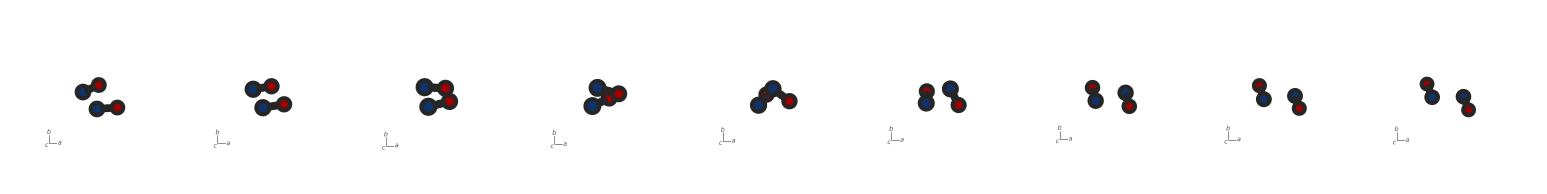

In [21]:
fig,axes = plt.subplots(ncols=len(results1.images),dpi=300)
style = RenderStyle(
    cell_style=CellEdgeStyle(
        line_width=0
    ),
)
for i,image in enumerate(results1.images):
    scene = StructureScene.from_pymatgen(aaa.get_structure(image))
    scene.view.zoom = 0.5  # Zoom in
    scene.render_mpl(ax=axes[i],style=style)

## step 2 

In [22]:
from smilesbox.smilesbox import SMILESbox 
import copy 
no2 = SMILESbox("N(=O)[O]") ; no2_atoms = copy.deepcopy(no2.atoms)
o2 = SMILESbox("O=O") ; o2_atoms = copy.deepcopy(o2.atoms)

In [28]:
nr = NEBRunner(calculator=CHGNetCalculator(use_device="cpu"),fmax=0.2,climb=False)

reacts,prods = nr._build_supercell_for_reaction(
    species_atoms = {"NO2":no2_atoms,"N2O2":n2o2_atoms,"O2":o2_atoms},
    reactant_stoich = {"N2O2":1,"O2":1},
    product_stoich = {"NO2":2},
    cell_size=5
                                 )
reacts,prods

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cpu


(Atoms(symbols='NONO3', pbc=True, cell=[5.0, 5.0, 5.0]),
 Atoms(symbols='NO2NO2', pbc=True, cell=[5.0, 5.0, 5.0]))

In [29]:
results2 = nr.run(initial=sort(reacts),final=sort(prods))


───────────────────────────────────────────────────────
NEB: neb
  6 atoms | 9 images | fmax=0.2 eV/Å | CI=False
  E(initial) = -35.6866 eV
  E(final)   = -39.6001 eV
  ΔE         = -3.9135 eV
  IDPP interpolation done — running NEB optimisation...


/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/ase/mep/neb.py:329: UserWarning: The default method has changed from 'aseneb' to 'improvedtangent'. The 'aseneb' method is an unpublished, custom implementation that is not recommended as it frequently results in very poor bands. Please explicitly set method='improvedtangent' to silence this warning, or set method='aseneb' if you strictly require the old behavior (results may vary). See: https://gitlab.com/ase/ase/-/merge_requests/3952
  warnings.warn(


KeyboardInterrupt: 

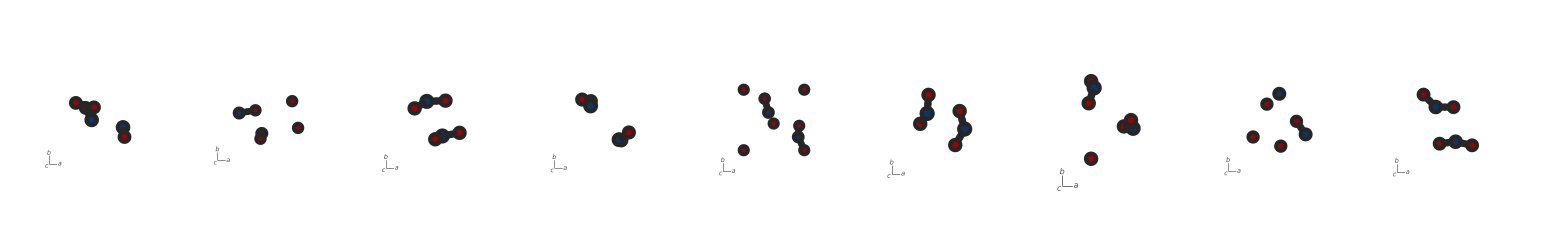

In [25]:
fig,axes = plt.subplots(ncols=len(results2.images),dpi=300)
style = RenderStyle(
    cell_style=CellEdgeStyle(
        line_width=0
    ),
)
for i,image in enumerate(results2.images):
    scene = StructureScene.from_pymatgen(aaa.get_structure(image))
    scene.view.zoom = 0.5  # Zoom in
    scene.render_mpl(ax=axes[i],style=style)

In [26]:
"""
microkinetic_model.py
---------------------
Microkinetic rate modelling from NEB barriers.

Given a sequence of elementary steps with forward/reverse barriers,
this module:

  1. Computes Eyring rate constants k(T) for each step
  2. Builds and integrates the ODE system for species concentrations
  3. Extracts the overall rate, turnover frequency, and rate-determining step
  4. Optionally derives the quasi-steady-state (QSS) analytical rate law
     for simple linear mechanisms

Physical assumptions
--------------------
- Gas-phase, ideal mixture: rate = k × [A] × [B] (collision frequency
  already folded into the pre-exponential via Eyring TST)
- Reversible elementary steps (both k_f and k_r computed from barriers)
- Concentration units: molecules per unit volume (normalised to 1 here;
  pass molar fractions or number densities as initial conditions)
- Temperature-independent barriers (no quantum tunnelling correction by
  default; enable Wigner below)

Eyring equation
---------------
    k(T) = (κ kB T / h) × exp(-Ea / kB T)

where κ is the transmission coefficient (default 1.0).
"""

from __future__ import annotations

import warnings
from dataclasses import dataclass, field
from typing import Optional

import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# Physical constants (SI)
kB_SI  = 1.380649e-23   # J/K
h_SI   = 6.62607015e-34 # J·s
kB_eV  = 8.617333e-5    # eV/K
NA     = 6.02214076e23  # mol⁻¹

# eV → J
eV_to_J = 1.602176634e-19


# ---------------------------------------------------------------------------
# Data structures
# ---------------------------------------------------------------------------

@dataclass
class ElementaryStep:
    """
    One reversible elementary step in the mechanism.

    reactants  : list of species names on the left  e.g. ['NO', 'O2']
    products   : list of species names on the right e.g. ['NO3']
    Ea_f_eV    : forward barrier from NEB (eV)
    Ea_r_eV    : reverse barrier from NEB (eV)
    label      : human-readable name
    kappa      : Eyring transmission coefficient (1 = classical, no tunnelling)

    The reaction energy is implied: ΔE = Ea_f - Ea_r
    """
    reactants: list[str]
    products:  list[str]
    Ea_f_eV:   float
    Ea_r_eV:   float
    label:     str = ""
    kappa:     float = 1.0

    def k_forward(self, T: float) -> float:
        """Forward rate constant (s⁻¹ or s⁻¹·[conc]^(n-1)) at temperature T (K)."""
        return _eyring(self.Ea_f_eV, T, self.kappa)

    def k_reverse(self, T: float) -> float:
        return _eyring(self.Ea_r_eV, T, self.kappa)

    def delta_E_eV(self) -> float:
        return self.Ea_f_eV - self.Ea_r_eV

    def equilibrium_constant(self, T: float) -> float:
        """Dimensionless Keq = kf / kr."""
        kr = self.k_reverse(T)
        return self.k_forward(T) / kr if kr > 0 else np.inf

    def summary(self, T: float) -> str:
        kf = self.k_forward(T)
        kr = self.k_reverse(T)
        return (
            f"  {self.label or '+'.join(self.reactants)+'→'+'+'.join(self.products)}\n"
            f"    Ea_f = {self.Ea_f_eV:.3f} eV  Ea_r = {self.Ea_r_eV:.3f} eV  "
            f"ΔE = {self.delta_E_eV():+.3f} eV\n"
            f"    k_f({T:.0f}K) = {kf:.3e} s⁻¹   k_r = {kr:.3e} s⁻¹   "
            f"Keq = {kf/kr if kr else np.inf:.3e}"
        )


@dataclass
class MechanismStep:
    """Associates an ElementaryStep with its stoichiometric coefficients."""
    step: ElementaryStep
    reactant_stoich: dict[str, int]   # e.g. {'NO': 2}
    product_stoich:  dict[str, int]   # e.g. {'N2O2': 1}


@dataclass
class MicrokineticResult:
    """All outputs from a microkinetic integration."""
    T_K: float
    t_span: tuple[float, float]
    species: list[str]
    t: np.ndarray                          # time axis
    concentrations: np.ndarray            # shape (n_species, n_time)
    rates: np.ndarray                     # shape (n_steps, n_time)
    overall_rate: float                   # d[product]/dt at quasi-steady state
    rate_determining_step: int            # index of rate-limiting step
    degree_of_rate_control: np.ndarray   # DRC per step
    converged: bool

    def summary(self, mechanism: list[MechanismStep]) -> str:
        lines = [f"\nMicrokinetic result at T = {self.T_K:.0f} K"]
        lines.append(f"  Overall rate = {self.overall_rate:.3e} (conc/s)")
        rds = mechanism[self.rate_determining_step].step.label or \
              f"Step {self.rate_determining_step+1}"
        lines.append(f"  Rate-determining step: {rds} "
                     f"(DRC = {self.degree_of_rate_control[self.rate_determining_step]:.3f})")
        lines.append(f"  Degree of rate control per step:")
        for i, ms in enumerate(mechanism):
            lbl = ms.step.label or f"Step {i+1}"
            lines.append(f"    [{i+1}] {lbl}: {self.degree_of_rate_control[i]:.3f}")
        return "\n".join(lines)


# ---------------------------------------------------------------------------
# Core physics
# ---------------------------------------------------------------------------

def _eyring(Ea_eV: float, T: float, kappa: float = 1.0) -> float:
    """Eyring TST rate constant in s⁻¹ (per-collision units)."""
    if T <= 0:
        return 0.0
    Ea_J = Ea_eV * eV_to_J
    prefactor = kappa * kB_SI * T / h_SI
    exponent  = -Ea_J / (kB_SI * T)
    # Guard against underflow
    if exponent < -700:
        return 0.0
    return prefactor * np.exp(exponent)


def _wigner_tunnelling(Ea_eV: float, T: float, nu_imag_cm1: float = 1000.0) -> float:
    """
    Wigner tunnelling correction factor (multiplicative on Eyring k).
    nu_imag_cm1: imaginary frequency of TS in cm⁻¹ (estimate from TS Hessian).
    Only significant for H-transfer steps at low T.
    """
    nu_Hz = nu_imag_cm1 * 2.998e10     # cm⁻¹ → Hz
    u = h_SI * nu_Hz / (kB_SI * T)
    return 1.0 + u**2 / 24.0


# ---------------------------------------------------------------------------
# ODE system builder
# ---------------------------------------------------------------------------

class MicrokineticModel:
    """
    Build and integrate the microkinetic ODE for a gas-phase mechanism.

    Parameters
    ----------
    mechanism    : list of MechanismStep objects
    species      : list of all species names (determines ODE dimension)
    T_K          : temperature in Kelvin
    wigner       : apply Wigner tunnelling correction
    nu_imag_cm1  : imaginary TS frequencies for Wigner (one per step)

    Example
    -------
    steps = [
        MechanismStep(
            step=ElementaryStep(['NO','O2'], ['NO3'],
                                Ea_f_eV=0.5, Ea_r_eV=1.2, label='NO+O2→NO3'),
            reactant_stoich={'NO':1, 'O2':1},
            product_stoich={'NO3':1},
        ),
        MechanismStep(
            step=ElementaryStep(['NO3','NO'], ['NO2'],
                                Ea_f_eV=0.2, Ea_r_eV=0.8, label='NO3+NO→2NO2'),
            reactant_stoich={'NO3':1, 'NO':1},
            product_stoich={'NO2':2},
        ),
    ]
    model = MicrokineticModel(steps, species=['NO','O2','NO3','NO2'], T_K=600)
    result = model.integrate({'NO':1.0, 'O2':0.5}, t_span=(0, 1e-3))
    print(result.summary(steps))
    """

    def __init__(
        self,
        mechanism: list[MechanismStep],
        species: list[str],
        T_K: float,
        wigner: bool = False,
        nu_imag_cm1: Optional[list[float]] = None,
    ):
        self.mechanism   = mechanism
        self.species     = species
        self.T_K         = T_K
        self.wigner      = wigner
        self.nu_imag_cm1 = nu_imag_cm1 or [1000.0] * len(mechanism)

        self._idx = {s: i for i, s in enumerate(species)}
        self._kf, self._kr = self._compute_rate_constants()

    def _compute_rate_constants(self) -> tuple[list[float], list[float]]:
        kf, kr = [], []
        for i, ms in enumerate(self.mechanism):
            kfi = ms.step.k_forward(self.T_K)
            kri = ms.step.k_reverse(self.T_K)
            if self.wigner:
                w = _wigner_tunnelling(ms.step.Ea_f_eV, self.T_K,
                                       self.nu_imag_cm1[i])
                kfi *= w
                kri *= w
            kf.append(kfi)
            kr.append(kri)
        return kf, kr

    def _net_rate(self, conc: np.ndarray, step_idx: int) -> float:
        """Net rate of step i = kf·∏[reactants]^stoich - kr·∏[products]^stoich."""
        ms = self.mechanism[step_idx]
        rf = self._kf[step_idx]
        rr = self._kr[step_idx]
        for sp, n in ms.reactant_stoich.items():
            c = max(conc[self._idx[sp]], 0.0)
            rf *= c ** n
        for sp, n in ms.product_stoich.items():
            c = max(conc[self._idx[sp]], 0.0)
            rr *= c ** n
        return rf - rr

    def _ode_rhs(self, t: float, conc: np.ndarray) -> np.ndarray:
        """d[species]/dt from all elementary steps."""
        dcdt = np.zeros(len(self.species))
        for i, ms in enumerate(self.mechanism):
            r = self._net_rate(conc, i)
            for sp, n in ms.reactant_stoich.items():
                dcdt[self._idx[sp]] -= n * r
            for sp, n in ms.product_stoich.items():
                dcdt[self._idx[sp]] += n * r
        return dcdt

    def integrate(
        self,
        initial_concentrations: dict[str, float],
        t_span: tuple[float, float] = (0, 1.0),
        n_points: int = 1000,
        method: str = "BDF",        # stiff-safe; use 'RK45' for non-stiff
        rtol: float = 1e-8,
        atol: float = 1e-12,
    ) -> MicrokineticResult:
        """
        Integrate the ODE system.

        Parameters
        ----------
        initial_concentrations : {species: concentration} — species not listed
                                 default to 0.
        t_span  : (t_start, t_end) in seconds
        n_points: number of output timepoints
        method  : scipy ODE solver ('BDF' for stiff systems, recommended)
        """
        c0 = np.zeros(len(self.species))
        for sp, val in initial_concentrations.items():
            if sp in self._idx:
                c0[self._idx[sp]] = val

        t_eval = np.linspace(t_span[0], t_span[1], n_points)

        sol = solve_ivp(
            self._ode_rhs, t_span, c0,
            method=method, t_eval=t_eval,
            rtol=rtol, atol=atol, dense_output=False,
        )

        converged = sol.success
        if not converged:
            warnings.warn(f"ODE integration did not converge: {sol.message}")

        # Per-step net rates at each timepoint
        rates = np.zeros((len(self.mechanism), len(sol.t)))
        for ti, conc in enumerate(sol.y.T):
            for i in range(len(self.mechanism)):
                rates[i, ti] = self._net_rate(conc, i)

        # Overall rate: production rate of the first listed product of last step
        # (use the quasi-steady-state tail — last 10% of trajectory)
        last_step  = self.mechanism[-1]
        first_prod = list(last_step.product_stoich.keys())[0]
        prod_idx   = self._idx[first_prod]
        tail_start = int(0.9 * len(sol.t))
        prod_conc  = sol.y[prod_idx, tail_start:]
        t_tail     = sol.t[tail_start:]

        if len(t_tail) > 1:
            overall_rate = float(np.polyfit(t_tail, prod_conc, 1)[0])
        else:
            overall_rate = 0.0

        # Rate-determining step: step with lowest average net rate in QSS tail
        mean_rates = np.mean(np.abs(rates[:, tail_start:]), axis=1)
        rds = int(np.argmin(mean_rates))

        # Degree of rate control (Campbell DRC): numerical perturbation
        drc = self._compute_drc(c0, t_span, overall_rate,
                                 method, rtol, atol)

        return MicrokineticResult(
            T_K=self.T_K,
            t_span=t_span,
            species=self.species,
            t=sol.t,
            concentrations=sol.y,
            rates=rates,
            overall_rate=overall_rate,
            rate_determining_step=rds,
            degree_of_rate_control=drc,
            converged=converged,
        )

    def _compute_drc(
        self,
        c0: np.ndarray,
        t_span: tuple,
        r_ref: float,
        method: str,
        rtol: float,
        atol: float,
        delta: float = 0.01,       # 1% perturbation on kf and kr
    ) -> np.ndarray:
        """
        Campbell degree of rate control:
          DRC_i = (∂ ln r / ∂ ln k_i) at constant Keq

        Numerical approximation: perturb kf_i and kr_i by +δ simultaneously
        (keeping Keq = kf/kr constant), reintegrate, measure change in rate.
        """
        drc = np.zeros(len(self.mechanism))
        if abs(r_ref) < 1e-30:
            return drc

        for i in range(len(self.mechanism)):
            # Save original
            kf_orig = self._kf[i]
            kr_orig = self._kr[i]

            # Perturb upward (keep Keq constant)
            self._kf[i] = kf_orig * (1 + delta)
            self._kr[i] = kr_orig * (1 + delta)

            t_eval = np.linspace(*t_span, 500)
            sol_p = solve_ivp(self._ode_rhs, t_span, c0,
                              method=method, t_eval=t_eval,
                              rtol=rtol, atol=atol)

            # Restore
            self._kf[i] = kf_orig
            self._kr[i] = kr_orig

            if not sol_p.success:
                drc[i] = 0.0
                continue

            last_step  = self.mechanism[-1]
            first_prod = list(last_step.product_stoich.keys())[0]
            prod_idx   = self._idx[first_prod]
            tail = int(0.9 * len(t_eval))
            prod_p = sol_p.y[prod_idx, tail:]
            t_p    = t_eval[tail:]
            r_p    = float(np.polyfit(t_p, prod_p, 1)[0]) if len(t_p) > 1 else 0.0

            # DRC ≈ (Δr/r) / (Δk/k) = (r_p - r_ref)/r_ref / delta
            drc[i] = ((r_p - r_ref) / r_ref) / delta if abs(r_ref) > 0 else 0.0

        return drc

    # ------------------------------------------------------------------
    # Analytical QSS rate law (linear mechanisms only)
    # ------------------------------------------------------------------

    def qss_rate_law(
        self,
        intermediate_species: list[str],
        initial_concentrations: dict[str, float],
    ) -> str:
        """
        Derive a symbolic quasi-steady-state rate expression for simple
        linear chain mechanisms.  Prints the analytical form and returns
        it as a string.

        Works for mechanisms where intermediates are consumed as fast as
        they are made (d[I]/dt ≈ 0).

        For the 2NO+O2 example:
            QSS on [NO3]: k1f[NO][O2] - k1r[NO3] - k2f[NO3][NO] = 0
            → [NO3]_ss = k1f[NO][O2] / (k1r + k2f[NO])
            → r_overall = k2f[NO3]_ss[NO] = k1f·k2f[NO]²[O2] / (k1r + k2f[NO])
        """
        kf = self._kf
        kr = self._kr

        lines = ["Quasi-steady-state rate law (analytical approximation):"]
        lines.append("")

        # For the specific 2-step case we can give the exact QSS expression
        if len(self.mechanism) == 2:
            ms1 = self.mechanism[0]
            ms2 = self.mechanism[1]

            # Step 1: A + B ⇌ I
            # Step 2: I + C ⇌ products
            r1_specs = list(ms1.reactant_stoich.keys())
            r2_specs = list(ms2.reactant_stoich.keys())

            k1f_val = kf[0]
            k1r_val = kr[0]
            k2f_val = kf[1]
            k2r_val = kr[1]

            # Concentrations at t=0
            c = {sp: initial_concentrations.get(sp, 0.0) for sp in self.species}

            # Symbolic expression
            lines.append(f"Step 1: {' + '.join(ms1.reactants)} ⇌ {' + '.join(ms1.products)}")
            lines.append(f"  k1f = {k1f_val:.3e} s⁻¹   k1r = {k1r_val:.3e} s⁻¹")
            lines.append(f"Step 2: {' + '.join(ms2.reactants)} ⇌ {' + '.join(ms2.products)}")
            lines.append(f"  k2f = {k2f_val:.3e} s⁻¹   k2r = {k2r_val:.3e} s⁻¹")
            lines.append("")

            # Find the intermediate (product of step 1, reactant of step 2)
            intermediates = set(ms1.product_stoich) & set(ms2.reactant_stoich)
            if intermediates:
                I = list(intermediates)[0]

                # QSS: k1f·∏[R1] - k1r·[I] - k2f·[I]·∏[R2_excl_I] = 0
                r2_excl = [s for s in ms2.reactant_stoich if s != I]
                r2_prod = np.prod([c[s] ** ms2.reactant_stoich[s]
                                   for s in r2_excl]) if r2_excl else 1.0
                r1_prod = np.prod([c[s] ** ms1.reactant_stoich[s]
                                   for s in ms1.reactants])

                I_ss_num = k1f_val * r1_prod
                I_ss_den = k1r_val + k2f_val * r2_prod
                I_ss     = I_ss_num / I_ss_den if I_ss_den > 0 else 0.0

                r_qss = k2f_val * I_ss * r2_prod

                lines.append(f"QSS on [{I}]:")
                lines.append(f"  [{I}]_ss = k1f·∏[R1] / (k1r + k2f·∏[R2])")
                lines.append(f"          = {I_ss:.3e}")
                lines.append("")
                lines.append(f"Overall rate (QSS):")
                lines.append(f"  r = k2f · [{I}]_ss · ∏[R2]")
                lines.append(f"    = k1f·k2f·∏[R1]·∏[R2] / (k1r + k2f·∏[R2])")
                lines.append(f"    = {r_qss:.3e}  (at initial concentrations)")

                # Rate-limiting regimes
                if k1r_val > k2f_val * r2_prod:
                    lines.append("")
                    lines.append("  Regime: k1r >> k2f·[R2]  →  step 1 pre-equilibrium")
                    lines.append(f"  r ≈ (k1f/k1r)·k2f·∏[R1]·∏[R2] = Keq1·k2f·∏[all]")
                else:
                    lines.append("")
                    lines.append("  Regime: k2f·[R2] >> k1r  →  step 1 rate-determining")
                    lines.append(f"  r ≈ k1f·∏[R1]  (step 2 fast, step 1 limits)")

        result = "\n".join(lines)
        print(result)
        return result

    # ------------------------------------------------------------------
    # Arrhenius fit across temperatures
    # ------------------------------------------------------------------

    def arrhenius_fit(
        self,
        T_range: tuple[float, float] = (300, 1000),
        n_T: int = 20,
        initial_concentrations: dict[str, float] = None,
        t_span: tuple[float, float] = (0, 1e-3),
    ) -> dict:
        """
        Integrate the microkinetic model at multiple temperatures and fit
        an effective Arrhenius expression to the overall rate:
            r(T) = A · exp(-Ea_eff / kB T)

        Returns dict with Ea_eff_eV, A, T_values, rates.
        """
        T_values = np.linspace(T_range[0], T_range[1], n_T)
        rates    = []
        c0 = initial_concentrations or {}

        for T in T_values:
            model_T = MicrokineticModel(
                self.mechanism, self.species, T_K=float(T),
                wigner=self.wigner,
            )
            try:
                res = model_T.integrate(c0, t_span=t_span, n_points=300)
                rates.append(max(res.overall_rate, 1e-100))
            except Exception:
                rates.append(1e-100)

        rates = np.array(rates)
        inv_T = 1.0 / T_values
        ln_r  = np.log(rates)
        # Linear fit: ln(r) = ln(A) - Ea_eff/(kB·T)
        coeffs = np.polyfit(inv_T, ln_r, 1)
        Ea_eff_eV = -coeffs[0] * kB_eV
        A_prefactor = np.exp(coeffs[1])

        return {
            "Ea_eff_eV":   Ea_eff_eV,
            "A_prefactor": A_prefactor,
            "T_values":    T_values,
            "rates":       rates,
        }


# ---------------------------------------------------------------------------
# Convenience builder from NEBResults
# ---------------------------------------------------------------------------

def mechanism_from_neb_results(
    neb_results: list,         # list of NEBResult from neb_runner.py
    step_definitions: list[dict],
    species: list[str],
    T_K: float,
) -> tuple[MicrokineticModel, list[MechanismStep]]:
    """
    Build a MicrokineticModel directly from a list of NEBResult objects.

    Parameters
    ----------
    neb_results      : list of NEBResult (one per elementary step, in order)
    step_definitions : list of dicts, each with keys:
                       'reactants'       : list[str]  — left-hand species
                       'products'        : list[str]  — right-hand species
                       'reactant_stoich' : dict[str,int]
                       'product_stoich'  : dict[str,int]
                       'label'           : str
    species          : full list of species names (for ODE dimension)
    T_K              : temperature in Kelvin

    Example
    -------
    neb_results = [result_step1, result_step2]
    step_defs = [
        dict(
            reactants=['NO','O2'], products=['NO3'],
            reactant_stoich={'NO':1,'O2':1},
            product_stoich={'NO3':1},
            label='NO+O2→NO3',
        ),
        dict(
            reactants=['NO3','NO'], products=['NO2'],
            reactant_stoich={'NO3':1,'NO':1},
            product_stoich={'NO2':2},
            label='NO3+NO→2NO2',
        ),
    ]
    model, mechanism = mechanism_from_neb_results(
        neb_results, step_defs,
        species=['NO','O2','NO3','NO2'],
        T_K=600,
    )
    """
    assert len(neb_results) == len(step_definitions), \
        "Must supply one NEBResult per step definition"

    mechanism = []
    for neb, defn in zip(neb_results, step_definitions):
        step = ElementaryStep(
            reactants = defn["reactants"],
            products  = defn["products"],
            Ea_f_eV   = neb.Ea_forward_eV,
            Ea_r_eV   = neb.Ea_reverse_eV,
            label     = defn.get("label", ""),
        )
        mechanism.append(MechanismStep(
            step             = step,
            reactant_stoich  = defn["reactant_stoich"],
            product_stoich   = defn["product_stoich"],
        ))

    model = MicrokineticModel(mechanism, species, T_K)
    return model, mechanism

In [39]:
neb_results = [results1, results2]
neb_results[0].Ea_forward_eV = 0.114
neb_results[1].Ea_forward_eV = 0.18
step_defs = [
        dict(
            reactants=['NO','NO'], products=['N2O2'],
            reactant_stoich={'NO':1,'NO':1},
            product_stoich={'N2O2':1},
            label='2NO→N2O2',
        ),
        dict(
            reactants=['N2O2','O2'], products=['NO2'],
            reactant_stoich={'N2O2':1,'O2':1},
            product_stoich={'NO2':2},
            label='N2O2+O2→2NO2',
        ),
    ]
model, mechanism = mechanism_from_neb_results(
        neb_results, step_defs,
        species=['NO','O2','N2O2','NO2'],
        T_K=298,
    )

print(mechanism[0].step.summary(700))
print(mechanism[1].step.summary(700))

  2NO→N2O2
    Ea_f = 0.114 eV  Ea_r = 0.019 eV  ΔE = +0.095 eV
    k_f(700K) = 2.204e+12 s⁻¹   k_r = 1.070e+13 s⁻¹   Keq = 2.060e-01
  N2O2+O2→2NO2
    Ea_f = 0.180 eV  Ea_r = 3.914 eV  ΔE = -3.734 eV
    k_f(700K) = 7.379e+11 s⁻¹   k_r = 9.726e-16 s⁻¹   Keq = 7.586e+26


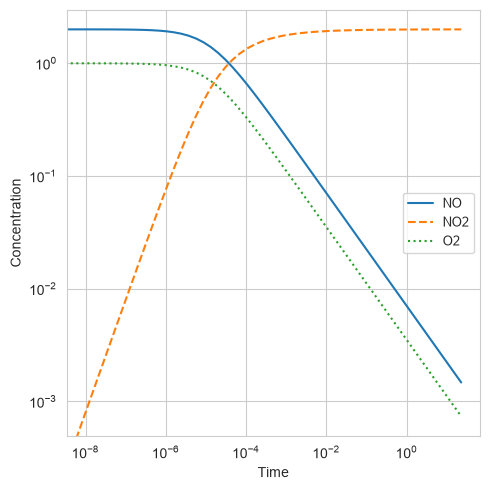

In [ ]:
from chempy import ReactionSystem,Reaction  # The rate constants below are arbitrary
from chempy.kinetics.ode import get_odesys
T = 700 
r1 = Reaction.from_string(f"2 NO -> N2O2 ; {mechanism[0].step.k_forward(T)}")
r2 = Reaction.from_string(f"N2O2 + O2 -> 2 NO2 ; {mechanism[1].step.k_forward(T)}")

rsys = ReactionSystem([r1,r2]) #

rsys = ReactionSystem(
    [Reaction.from_string("2 NO + O2 -> 2 NO2 ; 1e4")]
)

odesys, extra = get_odesys(rsys)
from collections import defaultdict
import numpy as np
tout = sorted(np.concatenate((np.linspace(0, 23), np.logspace(-8, 1))))
c0 = defaultdict(float, {'NO': 2, 'O2': 1, 'N2O2': 0, 'NO2': 0})
result = odesys.integrate(tout, c0, atol=1e-12, rtol=1e-14)
import matplotlib.pyplot as plt
import seaborn as sns 
sns.set_style("whitegrid")
sns.set_palette("pastel")
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
for ax in [axes]:
    _ = result.plot(names=[k for k in rsys.substances if k != 'H2O'], ax=ax)
    _ = ax.legend(loc='best', prop={'size': 9})
    _ = ax.set_xlabel('Time (s)')
    _ = ax.set_ylabel('Concentration (Arb. Units)')
#_ = axes[1].set_ylim([1e-13, 1e-1])
_ = axes.set_xscale('log')
_ = axes.set_yscale('log')
_ = fig.tight_layout()
plt.show()

In [47]:
rsys

In [37]:
result = model.integrate({"NO":2.0,"O2":1},t_span=(0,200))
print(result.summary(mechanism))


Microkinetic result at T = 298 K
  Overall rate = 0.000e+00 (conc/s)
  Rate-determining step: NO+O2→NO3 (DRC = 0.000)
  Degree of rate control per step:
    [1] NO+O2→NO3: 0.000
    [2] NO3+NO→2NO2: 0.000


In [303]:
np.mean(result.rates[1])

np.float64(0.0)

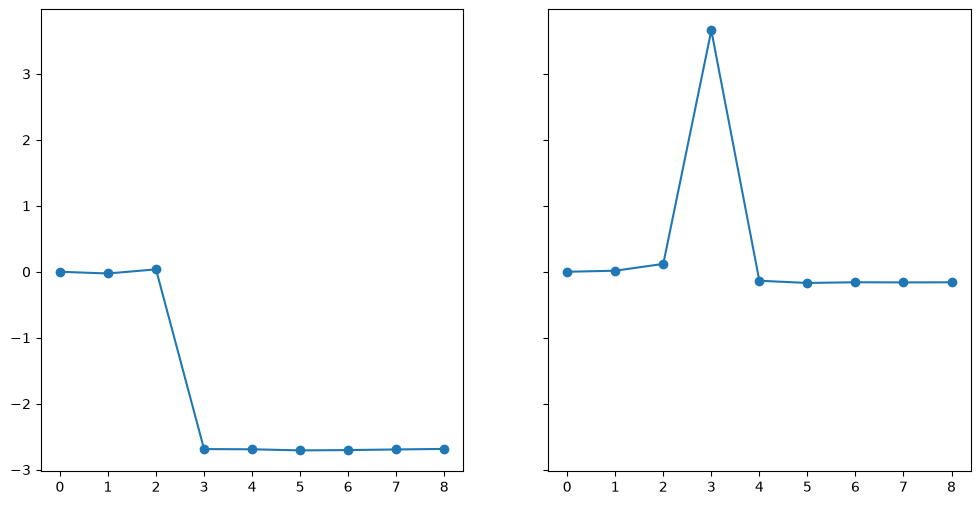

In [321]:
es1 = results1.image_energies_eV - results1.image_energies_eV[0]
es2 = results2.image_energies_eV - results2.image_energies_eV[0]

import matplotlib.pyplot as plt 

fig,ax = plt.subplots(ncols=2,figsize=(12,6),dpi=100,sharey=True)
ax[0].plot(np.arange(results1.n_images),es1,marker="o")
ax[1].plot(np.arange(results2.n_images),es2,marker="o")


In [322]:
arrh = model.arrhenius_fit(initial_concentrations={"NO":2.0,"O2":1})

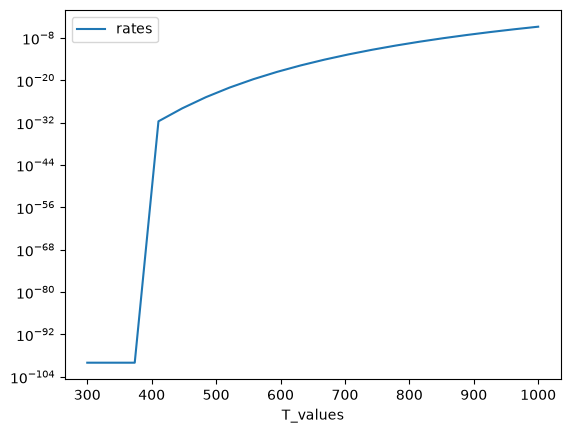

In [325]:
import pandas as pd 
ax = pd.DataFrame(arrh).plot.line(x="T_values",y="rates")
ax.set_yscale("log")